# Project Gigavolt - Phase 4
**Chunking -> embeddings -> vector database (ChromaDB, HNSW) -> search -> benchmark**

Run this notebook top to bottom (**Run All**). It uses the scripts in `src/`:
`chunker.py` (chunking engine), `embed.py` (embedding generation), `vectordb.py` (collection definition + search), `scale_corpus.py` (benchmark corpus growth).

| Section | What it shows |
|---|---|
| 1. Chunking | sentence-aware, overlapping, token-budgeted chunks from the 25 technical documents |
| 2. Embeddings | all-MiniLM-L6-v2 (384-d, L2-normalised) for every chunk |
| 3. Vector database | ChromaDB collection with metadata and an HNSW index; live similarity searches with latency |
| 4. Benchmark | HNSW tuning (M, ef_construction, ef_search): latency distribution and recall@k vs exact search |

**Targets:** median search latency < 20 ms; recall@5 > 0.9.

In [31]:
import json, sys, time, shutil, platform, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# find the project root (the folder containing src/) no matter where VS Code started the kernel
ROOT = Path.cwd().resolve()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import chromadb
import chunker, embed, scale_corpus as sc
import vectordb as vdb
from paths import MANUALS, RESULTS, INCIDENTS

RESULTS.mkdir(exist_ok=True)
SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 200)

print("project root:", ROOT)
print(f"python {platform.python_version()} | {platform.system()} {platform.machine()} | "
      f"{os.cpu_count()} CPUs | chromadb {chromadb.__version__}")

project root: <project-folder>
python 3.12.15 | Darwin arm64 | 10 CPUs | chromadb 1.5.9


## 1. Chunking
**Why chunk?** The embedding model reads at most 256 tokens, and one vector for a whole manual would blur many topics together. Small, focused chunks retrieve better.

**Design choices** (all configurable in `ChunkConfig`):
- **Token budget** counted with the embedding model's own tokenizer (128 body tokens + a short `[doc | title | section]` context prefix, well under the 256 limit). **Keep `max_tokens` at about 200 or less:** all-MiniLM-L6-v2 silently truncates anything beyond 256 tokens, so larger chunks (e.g. 512) would have their tails ignored; the embeddings cell reports how many chunks would be truncated.
- **Sentence boundaries:** chunks are built from whole sentences, never cut mid-sentence.
- **Overlap:** the next chunk starts with the last ~32 tokens (whole sentences) of the previous one, so a fact on a boundary is never lost.
- **Sticky headings:** a heading is never left at the end of a chunk; it stays with the text it introduces.
- **Tables:** extracted separately; each row becomes its own self-describing chunk ("Header: value; ...").

In [32]:
cfg = chunker.ChunkConfig(max_tokens=128, overlap_tokens=32, min_tokens=24)   # <- change and re-run to experiment
print(cfg, "\n")

chunks = chunker.chunk_corpus(MANUALS, cfg)
with open(RESULTS / "chunks.jsonl", "w", encoding="utf-8") as fh:
    for c in chunks:
        fh.write(json.dumps(c, ensure_ascii=False) + "\n")
print(f"\n{len(chunks)} chunks from {len({c['doc_id'] for c in chunks})} documents -> {RESULTS / 'chunks.jsonl'}")

ChunkConfig(max_tokens=128, overlap_tokens=32, min_tokens=24, max_table_row_tokens=220, context_prefix=True, table_rows_as_chunks=True, tokenizer_name='sentence-transformers/all-MiniLM-L6-v2') 

  GV-ECO-2024-019_Engineering_Change_Order.pdf                                  7 chunks
  GV-ECO-2024-031_Change_Order_-_Chiller_Relief_Valve.pdf                       6 chunks
  GV-ECO-2024-044_Change_Order_Re-torque.pdf                                    7 chunks
  GV-ECO-2024-052_Change_Order_Cabinet_Door_Seal.pdf                            7 chunks
  GV-INC-2024-088_Field_Incident_Investigation_Report.pdf                       8 chunks
  GV-INC-2024-104_Field_Incident_Report_Contactor_Flashover.pdf                 9 chunks
  GV-INC-2024-119_Field_Incident_Low_Isolation_Trip.pdf                         9 chunks
  GV-MAN-C1200-003_Manual.pdf                                                  14 chunks
  GV-MAN-G3500-002_Manual.pdf                                                  14 chunks
  GV

,chunks,median_tokens,max_tokens,table_rows
doc_id,,,,
GV-ECO-2024-019,7,105.0,126,0
GV-ECO-2024-031,6,121.5,128,0
GV-ECO-2024-044,7,97.0,106,0
GV-ECO-2024-052,7,96.0,113,0
GV-INC-2024-088,8,118.0,128,0
GV-INC-2024-104,9,110.0,126,0
GV-INC-2024-119,9,107.0,128,0
GV-MAN-C1200-003,14,106.0,120,4
GV-MAN-G3500-002,14,111.5,128,4


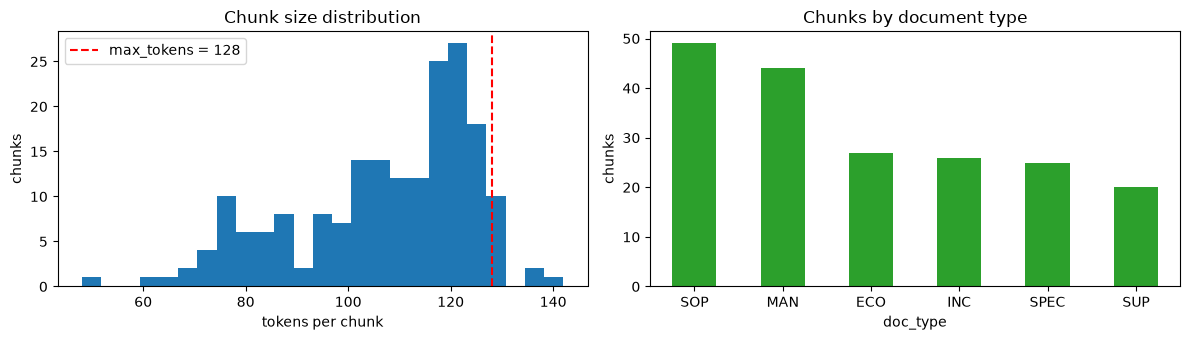

In [33]:
df_chunks = pd.DataFrame(chunks)
summary_docs = df_chunks.groupby("doc_id").agg(
    chunks=("id", "count"), median_tokens=("token_count", "median"), max_tokens=("token_count", "max"),
    table_rows=("chunk_type", lambda s: int((s == "table_row").sum())))
display(summary_docs)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(df_chunks.token_count, bins=25, color="tab:blue")
ax[0].axvline(cfg.max_tokens, color="r", ls="--", label=f"max_tokens = {cfg.max_tokens}")
ax[0].set(title="Chunk size distribution", xlabel="tokens per chunk", ylabel="chunks"); ax[0].legend()
df_chunks.doc_type.value_counts().plot.bar(ax=ax[1], color="tab:green", rot=0)
ax[1].set(title="Chunks by document type", ylabel="chunks")
plt.tight_layout(); plt.show()

In [34]:
def show(cid):
    c = next(x for x in chunks if x["id"] == cid)
    print(f"{c['id']}  [{c['chunk_type']}]  section={c['section']!r}  page={c['page']}  tokens={c['token_count']}")
    print("-" * 90); print(c["text"]); print()

# Pick a demo document that has at least 2 text chunks, so the overlap between consecutive chunks can be shown.
# (Prefers the warranty SOP; falls back to the document with the most chunks if you changed ChunkConfig.)
text_counts = pd.Series([c["doc_id"] for c in chunks if c["chunk_type"] == "text"]).value_counts()
assert len(text_counts), "no text chunks were produced - check the manuals/ folder and the chunking cell above"
DEMO_DOC = "GV-SOP-WAR-101" if text_counts.get("GV-SOP-WAR-101", 0) >= 2 else text_counts.index[0]
doc_chunks = [c for c in chunks if c["doc_id"] == DEMO_DOC and c["chunk_type"] == "text"]
print(f"demo document: {DEMO_DOC} ({len(doc_chunks)} text chunks at max_tokens={cfg.max_tokens})\n")

show(doc_chunks[0]["id"])
if len(doc_chunks) > 1:
    show(doc_chunks[1]["id"])
    shared = [s for s in chunker.split_sentences(doc_chunks[0]["text"]) if s in doc_chunks[1]["text"]]
    print("Sentences repeated in both consecutive chunks (the overlap window):")
    for s in shared:
        print("  >", s)
else:
    print("Every document fits in a single chunk at this size, so there is no overlap to show. "
          "Lower max_tokens (e.g. 128) to see overlapping chunks.")

print("\nText actually embedded (note the context prefix):")
print(doc_chunks[0]["embed_text"][:230], "...\n")

table_rows = [c for c in chunks if c["chunk_type"] == "table_row"]
if table_rows:
    print("A table row turned into its own chunk:")
    show(table_rows[0]["id"])

demo document: GV-SOP-WAR-101 (4 text chunks at max_tokens=128)

GV-SOP-WAR-101::c000  [text]  section='Purpose'  page=1  tokens=107
------------------------------------------------------------------------------------------
Standard Operating Procedure: Field Warranty Claims &
Technician Dispatch Protocol
Purpose This standard operating procedure guides Tier-2 and Tier-3 technical support agents and dispatch coordinators in translating customer field failure tickets and telemetry logs into authorized service dispatches (Technician_Dispatches) and formal claims (Warranty_Claims).
Warranty Eligibility Verification Matrix
Dispatch Workflow
1. Ticket Initiation: A ticket is opened in the relational database linking the customer ID, equipment unit serial number (Equipment_Units), and initial symptom description.

GV-SOP-WAR-101::c001  [text]  section='Dispatch Workflow'  page=2  tokens=94
------------------------------------------------------------------------------------------
1. Ticket In

## 2. Embeddings
`all-MiniLM-L6-v2` (SentenceTransformers): local, free, 384 dimensions, fast on CPU. Vectors are L2-normalised, so cosine similarity equals a dot product (which also makes exact ground truth in section 4 a single matrix multiply).

In [35]:
t0 = time.perf_counter()
model = embed.load_model()
print(f"model loaded in {time.perf_counter() - t0:.1f}s | max_seq_length = {model.max_seq_length} tokens | "
      f"dimension = {embed.embedding_dim(model)}")

texts = [c["embed_text"] for c in chunks]
print("chunks that would be truncated by the model:", embed.count_truncated(texts, model))

t0 = time.perf_counter()
E_real = embed.embed_texts(texts, model, batch_size=32, verbose=False)
dt = time.perf_counter() - t0
np.save(RESULTS / "embeddings.npy", E_real)
(RESULTS / "chunk_ids.json").write_text(json.dumps([c["id"] for c in chunks]))
print(f"embedded {len(texts)} chunks in {dt:.1f}s ({len(texts) / dt:.0f} chunks/s) -> matrix {E_real.shape}, {E_real.dtype}")
print("vector norms of the first 5 (should be 1.0):", np.round(np.linalg.norm(E_real[:5], axis=1), 4))

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 19288.03it/s]


model loaded in 0.3s | max_seq_length = 256 tokens | dimension = 384
chunks that would be truncated by the model: 0
embedded 191 chunks in 0.9s (219 chunks/s) -> matrix (191, 384), float32
vector norms of the first 5 (should be 1.0): [1. 1. 1. 1. 1.]


## 3. Vector database (ChromaDB + HNSW)
**Collection definition:** id `"<doc_id>::c<NNN>"` - 384-d normalised embedding - chunk text as the document - metadata: `doc_id, doc_type, source_file, title, chunk_index, chunk_type, section, page, token_count, ingested_at` (epoch seconds) `+ ingested_at_iso`.
**Index:** HNSW with cosine distance. **Why Chroma:** in-process Python library (no server), persistent, metadata filtering, exposes the HNSW parameters.

In [36]:
# 35 hand-written test questions and the document each should retrieve
HAND_QUERIES = [
    ("Which fault codes qualify for cell manufacturing defect warranty coverage?", "GV-SOP-WAR-101"),
    ("What happens to warranty if state of charge stays below 5% for more than 7 days?", "GV-SOP-WAR-101"),
    ("What is the termination resistance of the BMS CAN bus?", "GV-SPEC-BMS-ARC-01"),
    ("What does error ERR_BMS_301 module communication lost mean?", "GV-SPEC-BMS-ARC-01"),
    ("What is the thermal decomposition onset temperature of the LFP cell?", "GV-SPEC-CELL-LFP-08"),
    ("What is the cycle life of the Prismacell 280Ah cell?", "GV-SPEC-CELL-LFP-08"),
    ("What is the pouch swelling limit for the NMC cell?", "GV-SPEC-CELL-NMC-65"),
    ("At what temperature does NMC-811 begin self-heating?", "GV-SPEC-CELL-NMC-65"),
    ("What is the trigger current for the pyrofuse?", "GV-SPEC-FUSE-PYRO-04"),
    ("How do I safely test a pyrofuse bridge circuit?", "GV-SPEC-FUSE-PYRO-04"),
    ("What conductivity requires replacing the glycol filter cartridge?", "GV-SPEC-THERM-GLY-02"),
    ("What pH means the coolant must be flushed and refilled?", "GV-SPEC-THERM-GLY-02"),
    ("What non-conformances were found at the SinoPower slitting line?", "GV-SUP-AUD-502"),
    ("What was the SinoPower audit score?", "GV-SUP-AUD-502"),
    ("Who supplies the cathode precursor for the Megapack X-7000?", "GV-SUP-REP-401"),
    ("What do we do when ERR_BMS_701 exceeds 3.5% across a batch?", "GV-SUP-REP-401"),
    ("Which components are single-source risks and who is the second source?", "GV-SUP-REP-409"),
    ("Which supplier was quarantined under incident INC-2024-088?", "GV-SUP-REP-409"),
    ("Which retrofit kit fixes ERR_INV_404 on older Megapack units?", "GV-ECO-2024-019"),
    ("What replaced the brass pressure relief valve in the chiller glycol manifold?", "GV-ECO-2024-031"),
    ("What torque is required for the C-1200 cassette mounting ear fasteners?", "GV-ECO-2024-044"),
    ("Why was the G-3500 cabinet door gasket changed to EPDM?", "GV-ECO-2024-052"),
    ("What was the root cause of the thermal runaway at the Bakersfield facility?", "GV-INC-2024-088"),
    ("Why did the main contactor weld closed at the Rio Bravo plant?", "GV-INC-2024-104"),
    ("How did rodents cause the arc flash at Northlake Peaking Station?", "GV-INC-2024-119"),
    ("What arc flash PPE category is required to service the G-3500?", "GV-MAN-G3500-002"),
    ("How do I extract a cassette from the C-1200?", "GV-MAN-C1200-003"),
    ("How often is coolant conductivity tested on the X-7000?", "GV-MAN-X7000-001"),
    ("What voltage deviation is allowed when calibrating the cell voltage sense harness?", "GV-SOP-CAL-420"),
    ("How fast must pre-charge reach 95% of open-circuit voltage during site acceptance testing?", "GV-SOP-COMM-201"),
    ("What cell voltage must LFP systems be discharged to before decommissioning?", "GV-SOP-DECOM-601"),
    ("How long does flashing the master controller firmware take?", "GV-SOP-FIRM-105"),
    ("What is the refrigerant charge of the G-3500 chiller?", "GV-SOP-HVAC-310"),
    ("What happens in Stage 3 of the emergency escalation protocol?", "GV-SOP-SAFETY-900"),
    ("How long must a site be certified cold before technicians re-enter after a fire?", "GV-SOP-SAFETY-900"),
]

In [37]:
client_demo = chromadb.PersistentClient(path=str(RESULTS / "vectordb"))
col = vdb.create_collection(client_demo, "gigavolt_docs", M=16, ef_construction=200, ef_search=50)
secs = vdb.add_chunks(col, chunks, E_real)
print(f"collection 'gigavolt_docs' created via the {vdb.COLLECTION_API!r} API "
      f"(HNSW M=16, ef_construction=200, ef_search=50, cosine)")
print(f"ingested {col.count()} chunks in {secs:.2f}s | stored count == chunk count: {col.count() == len(chunks)}")
print("\nexample stored metadata:")
print(json.dumps(col.get(ids=[chunks[0]["id"]], include=["metadatas"])["metadatas"][0], indent=2))

collection 'gigavolt_docs' created via the 'configuration' API (HNSW M=16, ef_construction=200, ef_search=50, cosine)
ingested 191 chunks in 0.06s | stored count == chunk count: True

example stored metadata:
{
  "ingested_at": 1792967688,
  "chunk_type": "text",
  "section": "Engineering Change Order: Inverter Thyristor Snubber Assembly",
  "title": "Engineering Change Order",
  "page": 1,
  "doc_id": "GV-ECO-2024-019",
  "doc_type": "ECO",
  "ingested_at_iso": "2026-10-25T22:34:48+00:00",
  "token_count": 94,
  "source_file": "GV-ECO-2024-019_Engineering_Change_Order.pdf",
  "chunk_index": 0
}


In [38]:
for _ in range(3):                                           # warm-up: first query pays one-off index loading
    vdb.search(col, model.encode("warm up", normalize_embeddings=True), k=5)

def ask(question, k=5, where=None):
    t0 = time.perf_counter(); qv = model.encode(question, normalize_embeddings=True); t1 = time.perf_counter()
    res = vdb.search(col, qv, k=k, where=where); t2 = time.perf_counter()
    print(f"Q: {question}\n   query encoding {(t1 - t0) * 1000:.1f} ms | vector search {(t2 - t1) * 1000:.2f} ms")
    display(pd.DataFrame([dict(rank=i + 1, similarity=round(1 - d, 3), doc=m["doc_id"], type=m["chunk_type"],
                               section=m["section"], text=doc.replace("\n", " ")[:110])
                          for i, (d, m, doc) in enumerate(zip(res["distances"][0], res["metadatas"][0], res["documents"][0]))]))

ask("What conductivity requires replacing the glycol filter cartridge?")
ask("How do I safely test a pyrofuse bridge circuit?")
ask("Which retrofit kit fixes ERR_INV_404 on older Megapack units?")
ask("What is the termination resistance of the CAN bus?", where={"doc_type": "SPEC"})   # metadata filter

Q: What conductivity requires replacing the glycol filter cartridge?
   query encoding 3.8 ms | vector search 0.73 ms


,rank,similarity,doc,type,section,text
0,1,0.623,GV-SPEC-THERM-GLY-02,text,Critical Electrochemical Limits,Initial Fill Conductivity (Fresh Fluid): ≤ 0.2 µS/cm at 25 °C. Maximum Allowable In-Service Conductivity: 0.5
1,2,0.440,GV-SPEC-THERM-GLY-02,text,Scope,Material Specification: Industrial Inhibited Ethylene Glycol Heat Transfer Fluid Scope This specification gove
2,3,0.430,GV-MAN-C1200-003,text,Parts Inventory Correlation List,FLT-AIR-12: Washable electrostatically charged MERV-11 filter cartridge. HTR-CAB-100: Positive Temperature Coe
3,4,0.426,GV-SPEC-THERM-GLY-02,text,Chemical Composition & Purity Requirements,Freeze Protection Rating: Safe down to -37.0 °C (-34.6 °F). Boiling Point (at 1.0 bar): 108.5 °C (227.3 °F). C
4,5,0.408,GV-MAN-C1200-003,text,Decision Tree: Rapid Degradation or Premature Capacity Loss,"Recalibrate State of Charge (SoC) using manual balance routine. When ordering components for C-1200 repairs, e"


Q: How do I safely test a pyrofuse bridge circuit?
   query encoding 4.1 ms | vector search 0.72 ms


,rank,similarity,doc,type,section,text
0,1,0.559,GV-SPEC-FUSE-PYRO-04,text,Technical Parameters: High-Voltage Pyrofuse ACT-PYRO-1200,Total Physical Arc-Clearing Time: < 1.8 ms from receipt of command pulse. Handling Precautions: Pyrofuses cont
1,2,0.363,GV-INC-2024-119,text,Telemetry & Environmental Chronology,"Inverter DC overcurrent trip ERR_INV_404 logged. Main pyrofuses fire within 12 ms, isolating battery banks fro"
2,3,0.345,GV-SPEC-FUSE-PYRO-04,text,Technical Parameters: Part FUS-FAST-600A,"Melting Clearing Integral (I²t Rating): 42,000 A²s at rated voltage Terminal Geometry: Flush-end blade style w"
3,4,0.332,GV-SPEC-FUSE-PYRO-04,text,Technical Parameters: High-Voltage Pyrofuse ACT-PYRO-1200,"Internal Part Number: ACT-PYRO-1200 Application: Primary DC disconnect failsafe on Megapack X-7000 main 1,250"
4,5,0.293,GV-ECO-2024-019,text,Reason for Change,"Field telemetry logs from three operational utility installations (Unit Serial Numbers: SN-X7-0041, SN-X7-0089"


Q: Which retrofit kit fixes ERR_INV_404 on older Megapack units?
   query encoding 4.0 ms | vector search 0.74 ms


,rank,similarity,doc,type,section,text
0,1,0.639,GV-ECO-2024-019,text,Field Service & Retrofit Instructions,Field dispatches servicing Megapack units built prior to October 2024 showing persistent ERR_INV_404 fault log
1,2,0.584,GV-ECO-2024-019,text,Engineering Modification Details,3. Firmware Requirement: Inverter DSP firmware must be updated to version v2.4.11-b or later to adjust commuta
2,3,0.428,GV-INC-2024-104,text,Incident Reference: INC-2024-104,"Site Location: Rio Bravo Wind & Solar Hybrid Plant (Pecos County, TX) Equipment Affected: Gigavolt Megapack X-"
3,4,0.426,GV-INC-2024-119,text,"Incident Date: October 22, 2024","Investigating Lead: Sarah Kowalski, Senior Electrical Safety Compliance Specialist Incident Overview On Octobe"
4,5,0.406,GV-ECO-2024-019,text,Engineering Change Order: Inverter Thyristor Snubber Assembly,Engineering Change Order: Inverter Thyristor Snubber Assembly Upgrade ECO Tracking Identifier: ECO-2024-019 Ta


Q: What is the termination resistance of the CAN bus?
   query encoding 4.6 ms | vector search 1.02 ms


,rank,similarity,doc,type,section,text
0,1,0.380,GV-SPEC-BMS-ARC-01,text,Physical Layer & Wiring Specification,Topology: Linear daisy-chain bus utilizing shielded twisted-pair (STP) cabling (Part Number: HAR-CAN-35). Char
1,2,0.231,GV-SPEC-BMS-ARC-01,text,Frame Protocol & Sampling Timing,"If CAN heartbeat packet is missing for > 3 consecutive cycles (300 ms), the Master BMS trips error code ERR_BM"
2,3,0.200,GV-SPEC-BMS-ARC-01,text,Overview,System Architecture Specification: Master & Slave BMS Communication Topology Overview The Gigavolt Battery Man
3,4,0.192,GV-SPEC-CELL-LFP-08,text,Electro-Chemical & Physical Characteristics,Terminal Post Configuration: M6 laser-welded aluminum busbar studs (Torque limit: 8.0 N·m) Optimal Operating T
4,5,0.188,GV-SPEC-THERM-GLY-02,text,Chemical Composition & Purity Requirements,Freeze Protection Rating: Safe down to -37.0 °C (-34.6 °F). Boiling Point (at 1.0 bar): 108.5 °C (227.3 °F). C


In [39]:
QV_hand = embed.embed_texts([q for q, _ in HAND_QUERIES], model, verbose=False)
lat_demo = []
for qv in QV_hand:
    t = time.perf_counter(); vdb.search(col, qv, k=5, include=["distances"]); lat_demo.append((time.perf_counter() - t) * 1000)
print(f"vector search latency over {len(lat_demo)} questions on the real collection ({col.count()} vectors): "
      f"median {np.median(lat_demo):.2f} ms | p95 {np.percentile(lat_demo, 95):.2f} ms | max {max(lat_demo):.2f} ms   (target: median < 20 ms)")

vector search latency over 35 questions on the real collection (191 vectors): median 0.25 ms | p95 0.32 ms | max 0.54 ms   (target: median < 20 ms)


## 4. Benchmark: HNSW tuning, latency distribution, recall@k
- *Latency* = time of `collection.query(query_embeddings=...)` only; query *encoding* is timed separately.
- *Recall@k* = overlap of HNSW's top-k with the **exact** top-k (brute-force cosine). It measures index fidelity, not relevance; relevance (hit@k) is checked in section 4.8.

**Scale-up.** The real corpus is only ~200 chunks, so HNSW would be effectively exact for any setting and tuning would show nothing. For the benchmark the real chunks are augmented with the 100 real class incident reports and labelled **synthetic** chunks (recombined real sentences) up to `SCALE_TARGET` vectors. Synthetic data is used **only** for latency/recall; the relevance check uses the real corpus alone.

In [10]:
SCALE_TARGET = 5000            # total vectors in the benchmark corpus (lower, e.g. 2000, for a quicker run)
USE_INCIDENT_REPORTS = True    # the 100 real incident reports in data/incident_reports.txt
USE_SERVICE_RECORDS = False    # True + adapt SERVICE_SQL to also pull real ERP text from MariaDB
SERVICE_SQL = "SELECT service_log_id, full_service_context FROM Service_Logs WHERE full_service_context IS NOT NULL"

extra = []
if USE_INCIDENT_REPORTS:
    extra += sc.load_incident_reports(INCIDENTS)
if USE_SERVICE_RECORDS:
    extra += sc.load_service_records(SERVICE_SQL)
extra += sc.synthesize_chunks(chunks + extra, SCALE_TARGET, seed=SEED)
bench_chunks = chunks + extra
bench_ids = [c["id"] for c in bench_chunks]
assert len(set(bench_ids)) == len(bench_ids), "duplicate chunk ids"

cache_e, cache_i = RESULTS / "bench_embeddings.npy", RESULTS / "bench_ids.json"
if cache_e.exists() and cache_i.exists() and json.loads(cache_i.read_text()) == bench_ids:
    E_bench = np.load(cache_e); print("using cached benchmark embeddings")
else:
    t0 = time.perf_counter()
    E_extra = embed.embed_texts([c["embed_text"] for c in extra], model, batch_size=32, verbose=False)
    E_bench = np.vstack([E_real, E_extra]).astype(np.float32)
    np.save(cache_e, E_bench); cache_i.write_text(json.dumps(bench_ids))
    print(f"embedded {len(extra)} extra chunks in {time.perf_counter() - t0:.1f}s (cached for next time)")

id2idx = {cid: i for i, cid in enumerate(bench_ids)}
print(pd.Series([c["chunk_type"] for c in bench_chunks]).value_counts().to_string())
print("benchmark matrix:", E_bench.shape)

embedded 4809 extra chunks in 65.4s (cached for next time)
synthetic          4709
text                171
incident_report     100
table_row            20
benchmark matrix: (5000, 384)


### 4.1 Query set and exact ground truth
The 35 hand-written questions plus 300 sampled queries (random 8-15 word spans with ~15% of words dropped, to mimic imperfect phrasing). Ground truth = exact top-5 by cosine similarity.

In [11]:
def sampled_queries(chs, n, rng):
    out = []
    for i in rng.choice(len(chs), n, replace=True):
        words = chs[i]["text"].split()
        start = int(rng.integers(0, max(1, len(words) - 12)))
        piece = words[start:start + int(rng.integers(8, 16))]
        kept = [w for w in piece if rng.random() > 0.15]
        out.append(" ".join(kept or piece))
    return out

N_SAMPLED = 300
all_queries = [q for q, _ in HAND_QUERIES] + sampled_queries(bench_chunks, N_SAMPLED, rng)
QE = embed.embed_texts(all_queries, model, verbose=False)

enc_ms = []                                                   # encoding cost as a user would experience it
for q in all_queries[:60]:
    t = time.perf_counter(); model.encode(q, normalize_embeddings=True, show_progress_bar=False)
    enc_ms.append((time.perf_counter() - t) * 1000)
ENCODE_P50 = float(np.percentile(enc_ms, 50))
print(f"{len(all_queries)} queries; single-query encode latency p50 = {ENCODE_P50:.1f} ms")

K = 5
GT = np.argsort(-(QE @ E_bench.T), axis=1)[:, :K]             # exact top-K row indices per query
print("exact ground truth computed:", GT.shape)

335 queries; single-query encode latency p50 = 4.2 ms
exact ground truth computed: (335, 5)


### 4.2 Helpers
`measure()` runs 20 warm-up queries (not recorded), then times every query individually with `time.perf_counter()`.

In [12]:
BENCH_DB = RESULTS / "vectordb_bench"
shutil.rmtree(BENCH_DB, ignore_errors=True)
client = chromadb.PersistentClient(path=str(BENCH_DB))

def build(M, efc, efs, name):
    col_ = vdb.create_collection(client, name, M, efc, efs)
    secs_ = vdb.add_chunks(col_, bench_chunks, E_bench)
    return col_, secs_

def measure(col_, qvecs, k=K, warmup=20):
    for q in qvecs[:warmup]:
        vdb.search(col_, q, k=k, include=["distances"])
    lat_, found_ = [], []
    for q in qvecs:
        t = time.perf_counter()
        r = vdb.search(col_, q, k=k, include=["distances"])
        lat_.append((time.perf_counter() - t) * 1000)
        found_.append([id2idx[i] for i in r["ids"][0]])
    return np.array(lat_), found_

def recall_at(found, gt, k):
    return float(np.mean([len(set(f[:k]) & set(g[:k])) / k for f, g in zip(found, gt)]))

### 4.3 HNSW parameter grid
| Parameter | Meaning | Higher value means |
|---|---|---|
| **M** | graph connections per node | better recall, more memory, slower build |
| **ef_construction** | search breadth while *building* | better graph quality, slower build |
| **ef_search** | search breadth at *query* time | better recall, slower queries |

Every (M, ef_construction, ef_search) combination is built as its **own collection**. (Changing ef_search on an existing collection was found not to take effect in the tested Chroma version: recall was identical for every ef_search value, so the in-place approach was dropped.) Deliberately weak settings (M=4, ef_search=5) are included so the trade-off is visible even on a small corpus.

In [13]:
M_VALUES   = [4, 8, 16, 32]
EFC_VALUES = [50, 200]
EFS_VALUES = [5, 10, 25, 50, 100]

rows, latencies = [], {}
for M in M_VALUES:
    for efc in EFC_VALUES:
        first = len(rows)
        for efs in EFS_VALUES:
            name = f"bench_M{M}_efc{efc}_efs{efs}"
            before = vdb.dir_size_mb(str(BENCH_DB))
            col_b, build_s = build(M, efc, efs, name)            # ef_search is set at creation, one collection per value
            size_mb = vdb.dir_size_mb(str(BENCH_DB)) - before
            lat_b, found = measure(col_b, QE)
            latencies[(M, efc, efs)] = lat_b
            rows.append(dict(M=M, ef_construction=efc, ef_search=efs,
                             build_s=round(build_s, 2), index_mb=round(size_mb, 1),
                             p50_ms=np.percentile(lat_b, 50), p95_ms=np.percentile(lat_b, 95),
                             p99_ms=np.percentile(lat_b, 99), mean_ms=lat_b.mean(),
                             recall_at_1=recall_at(found, GT, 1), recall_at_5=recall_at(found, GT, 5)))
            client.delete_collection(name)                       # free memory/disk before the next build
        r5 = [round(r["recall_at_5"], 3) for r in rows[first:]]
        print(f"M={M:>2} efc={efc:>3}  recall@5 for ef_search {EFS_VALUES}: {r5}")

df = pd.DataFrame(rows)
df.to_csv(RESULTS / "hnsw_grid_results.csv", index=False)
print("Chroma index-config API used:", vdb.COLLECTION_API)
display(df.round(3).sort_values(["M", "ef_construction", "ef_search"]).reset_index(drop=True))

M= 4 efc= 50  recall@5 for ef_search [5, 10, 25, 50, 100]: [0.401, 0.503, 0.663, 0.813, 0.916]
M= 4 efc=200  recall@5 for ef_search [5, 10, 25, 50, 100]: [0.368, 0.47, 0.71, 0.807, 0.928]
M= 8 efc= 50  recall@5 for ef_search [5, 10, 25, 50, 100]: [0.681, 0.798, 0.913, 0.975, 0.987]
M= 8 efc=200  recall@5 for ef_search [5, 10, 25, 50, 100]: [0.71, 0.848, 0.946, 0.986, 0.993]
M=16 efc= 50  recall@5 for ef_search [5, 10, 25, 50, 100]: [0.779, 0.892, 0.952, 0.986, 0.998]
M=16 efc=200  recall@5 for ef_search [5, 10, 25, 50, 100]: [0.847, 0.93, 0.984, 0.996, 0.999]
M=32 efc= 50  recall@5 for ef_search [5, 10, 25, 50, 100]: [0.789, 0.892, 0.961, 0.984, 0.998]
M=32 efc=200  recall@5 for ef_search [5, 10, 25, 50, 100]: [0.849, 0.945, 0.986, 0.999, 1.0]
Chroma index-config API used: configuration


,M,ef_construction,ef_search,build_s,index_mb,p50_ms,p95_ms,p99_ms,mean_ms,recall_at_1,recall_at_5
0,4,50,5,2.92,39.1,0.304,0.342,0.390,0.308,0.415,0.401
1,4,50,10,3.18,20.2,0.318,0.355,0.385,0.322,0.516,0.503
2,4,50,25,3.60,8.1,0.355,0.413,0.441,0.362,0.693,0.663
3,4,50,50,3.68,15.7,0.437,0.668,0.963,0.472,0.824,0.813
4,4,50,100,3.69,8.3,0.523,0.613,0.693,0.529,0.925,0.916
5,4,200,5,3.66,15.5,0.302,0.332,0.364,0.305,0.394,0.368
6,4,200,10,3.97,8.2,0.319,0.355,0.387,0.323,0.487,0.470
7,4,200,25,3.69,7.9,0.354,0.408,0.431,0.360,0.722,0.710
8,4,200,50,3.79,7.9,0.417,0.504,0.523,0.425,0.824,0.807
9,4,200,100,3.66,7.9,0.524,0.632,0.698,0.533,0.937,0.928


### 4.4 Trade-off plots

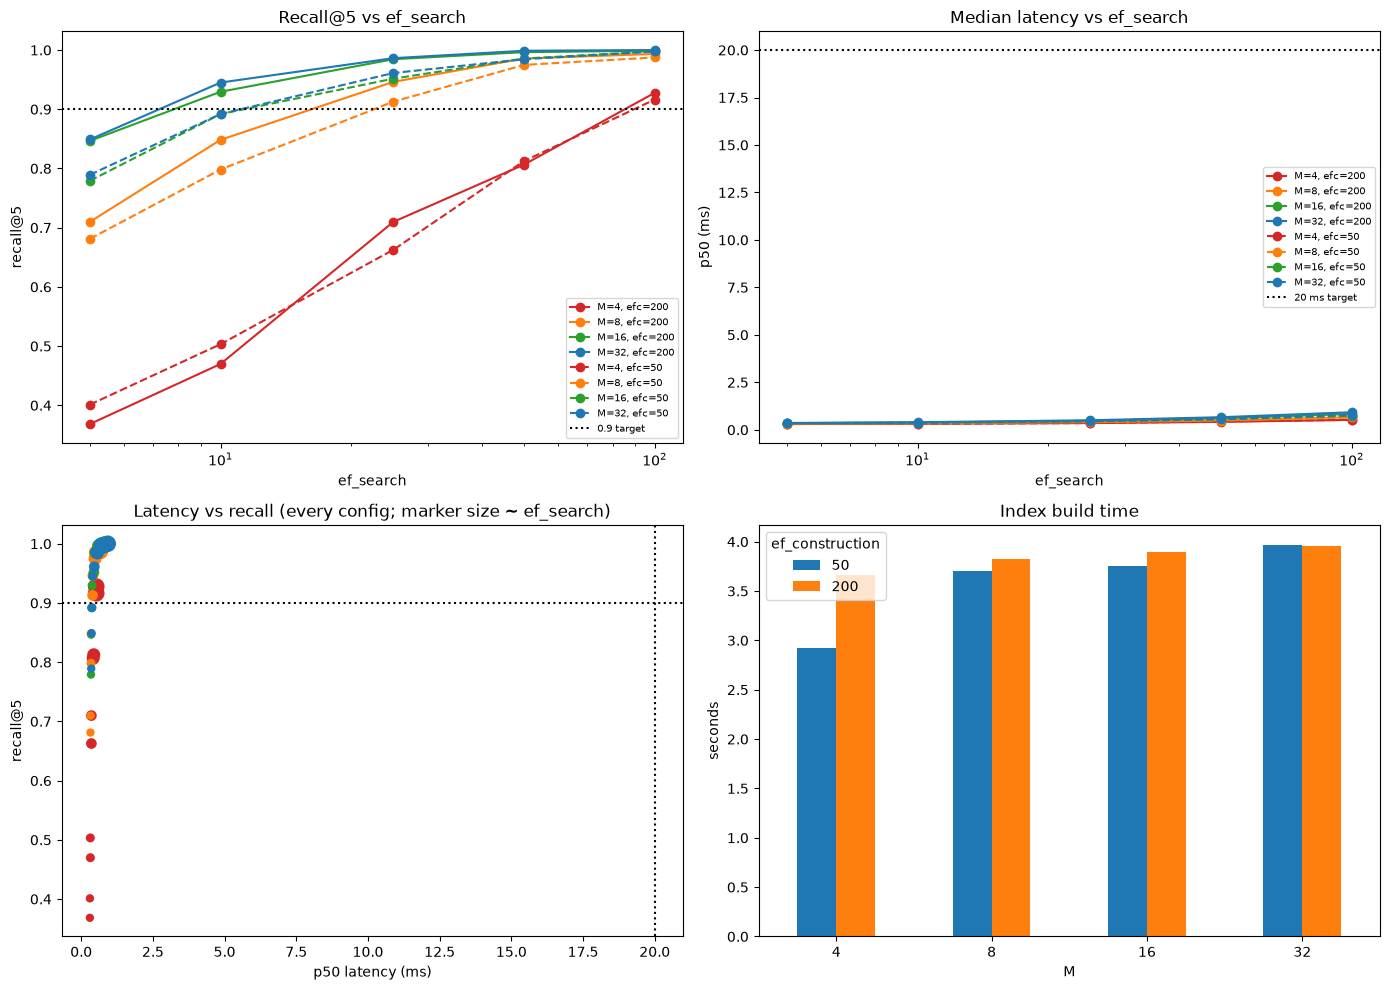

In [14]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
colors = {4: "tab:red", 8: "tab:orange", 16: "tab:green", 32: "tab:blue"}

for efc, ls in [(EFC_VALUES[-1], "-"), (EFC_VALUES[0], "--")]:
    for M in M_VALUES:
        s = df[(df.M == M) & (df.ef_construction == efc)].sort_values("ef_search")
        ax[0, 0].plot(s.ef_search, s.recall_at_5, ls, marker="o", color=colors[M], label=f"M={M}, efc={efc}")
        ax[0, 1].plot(s.ef_search, s.p50_ms, ls, marker="o", color=colors[M], label=f"M={M}, efc={efc}")
ax[0, 0].axhline(0.9, color="k", ls=":", label="0.9 target"); ax[0, 0].set(title="Recall@5 vs ef_search", xlabel="ef_search", ylabel="recall@5", xscale="log")
ax[0, 1].axhline(20, color="k", ls=":", label="20 ms target"); ax[0, 1].set(title="Median latency vs ef_search", xlabel="ef_search", ylabel="p50 (ms)", xscale="log")
ax[0, 0].legend(fontsize=7); ax[0, 1].legend(fontsize=7)

ax[1, 0].scatter(df.p50_ms, df.recall_at_5, c=[colors[m] for m in df.M], s=20 + df.ef_search)
ax[1, 0].axhline(0.9, color="k", ls=":"); ax[1, 0].axvline(20, color="k", ls=":")
ax[1, 0].set(title="Latency vs recall (every config; marker size ~ ef_search)", xlabel="p50 latency (ms)", ylabel="recall@5")

b = df.drop_duplicates(["M", "ef_construction"]).pivot(index="M", columns="ef_construction", values="build_s")
b.plot.bar(ax=ax[1, 1]); ax[1, 1].set(title="Index build time", ylabel="seconds", xlabel="M"); ax[1, 1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(RESULTS / "hnsw_tradeoffs.png", dpi=150); plt.show()

### 4.5 Choose the configuration and show the latency distribution
Rule: among configurations with **p50 < 20 ms**, take the cheapest (lowest p50) that reaches **recall@5 >= 0.95**; fall back to >= 0.90 if none do.

CHOSEN: M=16, ef_construction=50, ef_search=25 -> p50=0.44 ms, p95=0.51 ms, recall@5=0.952


,search_only_ms,encode_ms,search+encode_ms
P50,0.44,4.19,4.63
P90,0.50,NaN,NaN
P95,0.51,NaN,NaN
P99,0.56,NaN,NaN
min,0.35,NaN,NaN
max,0.62,NaN,NaN


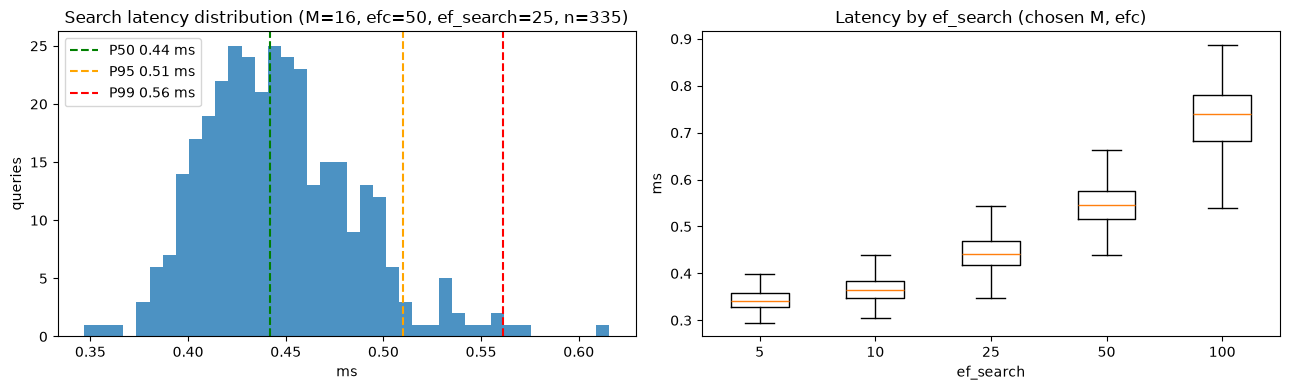

Brute-force numpy p50 over 5000 vectors: 0.10 ms (HNSW p50: 0.44 ms). Brute force is competitive at this scale; the ANN advantage appears as the corpus grows.


In [15]:
def pick(d, min_recall):
    ok = d[(d.p50_ms < 20) & (d.recall_at_5 >= min_recall)]
    return ok.sort_values(["p50_ms", "build_s"]).iloc[0] if len(ok) else None

CHOSEN = pick(df, 0.95)
if CHOSEN is None:
    CHOSEN = pick(df, 0.90)
if CHOSEN is None:
    CHOSEN = df.sort_values("recall_at_5", ascending=False).iloc[0]
    print("WARNING: no configuration met both targets; showing the highest-recall configuration.")
cM, cEFC, cEFS = int(CHOSEN.M), int(CHOSEN.ef_construction), int(CHOSEN.ef_search)
print(f"CHOSEN: M={cM}, ef_construction={cEFC}, ef_search={cEFS} -> "
      f"p50={CHOSEN.p50_ms:.2f} ms, p95={CHOSEN.p95_ms:.2f} ms, recall@5={CHOSEN.recall_at_5:.3f}")

lat = latencies[(cM, cEFC, cEFS)]
pct = {f"P{p}": float(np.percentile(lat, p)) for p in (50, 90, 95, 99)}
pct.update(min=float(lat.min()), max=float(lat.max()))
summary = pd.DataFrame({"search_only_ms": pct})
summary.loc["P50", "encode_ms"] = ENCODE_P50
summary.loc["P50", "search+encode_ms"] = pct["P50"] + ENCODE_P50
display(summary.round(2))

fig, a = plt.subplots(1, 2, figsize=(13, 4))
a[0].hist(lat, bins=40, color="tab:blue", alpha=.8)
for name, c in [("P50", "green"), ("P95", "orange"), ("P99", "red")]:
    a[0].axvline(pct[name], color=c, ls="--", label=f"{name} {pct[name]:.2f} ms")
a[0].set(title=f"Search latency distribution (M={cM}, efc={cEFC}, ef_search={cEFS}, n={len(lat)})", xlabel="ms", ylabel="queries"); a[0].legend()
a[1].boxplot([latencies[(cM, cEFC, e)] for e in EFS_VALUES], showfliers=False); a[1].set_xticklabels(EFS_VALUES)
a[1].set(title="Latency by ef_search (chosen M, efc)", xlabel="ef_search", ylabel="ms")
plt.tight_layout(); plt.savefig(RESULTS / "latency_distribution.png", dpi=150); plt.show()

# context: exact brute-force search over the same vectors (why use ANN at all?)
bf = []
for q in QE:
    t = time.perf_counter(); np.argpartition(-(E_bench @ q), K)[:K]; bf.append((time.perf_counter() - t) * 1000)
print(f"Brute-force numpy p50 over {len(E_bench)} vectors: {np.percentile(bf, 50):.2f} ms "
      f"(HNSW p50: {pct['P50']:.2f} ms). Brute force is competitive at this scale; the ANN advantage appears as the corpus grows.")

### 4.8 Relevance check on the REAL corpus (no synthetic data)
Recall measures ANN fidelity; this checks whether retrieval surfaces the right *document* for the hand-written questions (hit@k).

In [16]:
col_real = vdb.create_collection(client, "gigavolt_docs_real", cM, cEFC, cEFS)
vdb.add_chunks(col_real, chunks, E_real)

rel = []
for (q, expected), qv in zip(HAND_QUERIES, QE[:len(HAND_QUERIES)]):
    r = vdb.search(col_real, qv, k=5, include=["metadatas"])
    docs = [m["doc_id"] for m in r["metadatas"][0]]
    rank = docs.index(expected) + 1 if expected in docs else None
    rel.append(dict(query=q, expected=expected, rank=rank, top1=docs[0]))
rel = pd.DataFrame(rel)
for k in (1, 3, 5):
    print(f"hit@{k}: {(rel['rank'].fillna(99) <= k).mean():.2f}")
rel.to_csv(RESULTS / "relevance_results.csv", index=False)
display(rel[rel["rank"].isna() | (rel["rank"] > 1)])      # questions where the expected document was not first

hit@1: 0.94
hit@3: 1.00
hit@5: 1.00


,query,expected,rank,top1
4,What is the thermal decomposition onset temperature of the LFP cell?,GV-SPEC-CELL-LFP-08,2,GV-MAN-X7000-001
29,How fast must pre-charge reach 95% of open-circuit voltage during site acceptance testing?,GV-SOP-COMM-201,2,GV-INC-2024-104
